# 01 - EDA AND CLEANING

In [112]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import random
import math
import re

print("libraries imported successfully")

libraries imported successfully


# LOAD THE DATA INTO A PANDAS DATAFRAME

In [113]:
df = pd.read_csv("data/raw/mobile_phone_price.csv")

df

,Brand,Model,Storage,RAM,Screen Size (inches),Camera (MP),Battery Capacity (mAh),Price ($)
0,Apple,iPhone 13 Pro,128 GB,6 GB,6.1,12 + 12 + 12,3095,999
1,Samsung,Galaxy S21 Ultra,256 GB,12 GB,6.8,108 + 10 + 10 + 12,5000,1199
2,OnePlus,9 Pro,128 GB,8 GB,6.7,48 + 50 + 8 + 2,4500,899
3,Xiaomi,Redmi Note 10 Pro,128 GB,6 GB,6.67,64 + 8 + 5 + 2,5020,279
4,Google,Pixel 6,128 GB,8 GB,6.4,50 + 12.2,4614,799
...,...,...,...,...,...,...,...,...
402,Samsung,Galaxy Note20 5G,128,8,6.7,12+64+12,4300,1049
403,Xiaomi,Mi 10 Lite 5G,128,6,6.57,48+8+2+2,4160,349
404,Apple,iPhone 12 Pro Max,128,6,6.7,12+12+12,3687,1099
405,Oppo,Reno3,128,8,6.4,48+13+8+2,4025,429


# INSPECT THE DATA

In [114]:
print("\nshape of the dataset",df.shape)
print('\nFeature Names')
print(df.columns.tolist())
print('\nBasic Information')
print(df.info())


shape of the dataset (407, 8)

Feature Names
['Brand', 'Model', 'Storage ', 'RAM ', 'Screen Size (inches)', 'Camera (MP)', 'Battery Capacity (mAh)', 'Price ($)']

Basic Information
<class 'pandas.DataFrame'>
RangeIndex: 407 entries, 0 to 406
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Brand                   407 non-null    str  
 1   Model                   407 non-null    str  
 2   Storage                 407 non-null    str  
 3   RAM                     407 non-null    str  
 4   Screen Size (inches)    407 non-null    str  
 5   Camera (MP)             407 non-null    str  
 6   Battery Capacity (mAh)  407 non-null    int64
 7   Price ($)               407 non-null    str  
dtypes: int64(1), str(7)
memory usage: 25.6 KB
None


# Data Formatting

In [115]:
df.columns=df.columns.str.strip()
df['Storage']=df['Storage'].str.replace('GB','').astype(int)
df['RAM']=df['RAM'].str.replace('GB','').astype(int)
df['Price ($)']=df['Price ($)'].str.replace('$','').str.replace(',','').astype(int)
df['Screen Size (inches)'] = df['Screen Size (inches)'].str.extract(r'(\d+\.?\d*)')[0].astype(float)


# CAMERA FEATURE ENGINEERING

In [116]:
def parse_lenses(val):
    #'48+12+5MP' -> [48.0, 12.0, 5.0]. Returns [] if nothing parseable.
    if pd.isna(val):
        return []
    lenses = []
    for part in str(val).split('+'):
        m = re.search(r'(\d*\.?\d+)', part)   
        if m:
            lenses.append(float(m.group(1)))
    return lenses


def positional_features(lenses):
    # One column per lens position; a missing lens is 0 MP.
    lenses = lenses[:4]                        
    padded = lenses + [0.0] * (4 - len(lenses))
    return pd.Series({
        'num_camera':       len(lenses),
        'main_camera_mp':   padded[0],
        'second_camera_mp': padded[1],
        'third_camera_mp':  padded[2],
        'fourth_camera_mp': padded[3],
    })


camera_cols = ['num_camera', 'main_camera_mp', 'second_camera_mp',
               'third_camera_mp', 'fourth_camera_mp']

lens_list = df['Camera (MP)'].apply(parse_lenses)

# Inspect rows that failed instead of crashing on them
bad = df[~lens_list.apply(len).between(1, 4)]
if not bad.empty:
    print("Rows with 0 or >4 parsed lenses:")
    print(bad['Camera (MP)'].value_counts(dropna=False))

df = pd.concat([df, lens_list.apply(positional_features)], axis=1)
df[camera_cols] = df[camera_cols].map(math.ceil).astype(int)

In [117]:
# sanity check done, drop the raw camera string
df = df.drop(columns=['Camera (MP)'])

# DESCRIBE THE DATA

In [118]:
display(df.describe().round(2))
print('\nNumber of Unique Brands: ',df['Brand'].nunique())
print('Number of Unique Models: ',df['Model'].nunique())

,Storage,RAM,Screen Size (inches),Battery Capacity (mAh),Price ($),num_camera,main_camera_mp,second_camera_mp,third_camera_mp,fourth_camera_mp
count,407.00,407.00,407.00,407.00,407.00,407.00,407.00,407.00,407.00,407.00
mean,123.05,5.84,6.47,4676.48,408.31,3.14,43.33,9.13,3.64,1.03
std,64.96,2.43,0.32,797.19,299.68,0.78,24.66,10.18,4.90,1.73
min,32.00,2.00,4.50,1821.00,99.00,1.00,8.00,0.00,0.00,0.00
25%,64.00,4.00,6.44,4300.00,199.00,3.00,13.00,2.00,2.00,0.00
50%,128.00,6.00,6.50,5000.00,299.00,3.00,48.00,8.00,2.00,0.00
75%,128.00,8.00,6.59,5000.00,499.00,4.00,64.00,12.00,5.00,2.00
max,512.00,16.00,7.60,7000.00,1999.00,4.00,108.00,64.00,48.00,12.00



Number of Unique Brands:  16
Number of Unique Models:  239


# CHECK FOR MISSING DATA

In [119]:
print("\nMissing values:")
display(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values:


Brand                     0
Model                     0
Storage                   0
RAM                       0
Screen Size (inches)      0
Battery Capacity (mAh)    0
Price ($)                 0
num_camera                0
main_camera_mp            0
second_camera_mp          0
third_camera_mp           0
fourth_camera_mp          0
dtype: int64


Total missing values:
0


# CHECK FOR DUPLICATE DATA

In [120]:
duplicates=df.duplicated().sum()
print('Number of duplicate rows: ',duplicates)

if duplicates>0:
    df=df.drop_duplicates()
    print('\nDuplicates removed')
else:
    print('No duplicates')

Number of duplicate rows:  49

Duplicates removed


# BASIC DATA CLEANING

In [121]:
df.columns = [
    "Brand",
    "Model",
    "Storage",
    "RAM",
    "Screen_size",
    "Battery_cap",
    "Price",
    "num_camera",
    "main_camera_mp",
    "second_camera_mp",
    "third_camera_mp",
    "fourth_camera_mp"
]

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['Brand', 'Model', 'Storage', 'RAM', 'Screen_size', 'Battery_cap', 'Price', 'num_camera', 'main_camera_mp', 'second_camera_mp', 'third_camera_mp', 'fourth_camera_mp']


# GROUP RARE BRANDS INTO `Other`

In [122]:
MIN_BRAND_COUNT = 8   

brand_counts = df['Brand'].value_counts()
rare = brand_counts[brand_counts < MIN_BRAND_COUNT].index.tolist()
assert 'Other' not in brand_counts.index, "'Other# see Assumptions' is already a brand name"
# GROUP RARE BRANDS INTO `Other`
brand_raw = df['Brand'].copy()   # kept only for the exploration plots
df['Brand'] = df['Brand'].where(~df['Brand'].isin(rare), 'Other')

print(f"Brands with fewer than {MIN_BRAND_COUNT} phones, now grouped as 'Other':")
print(brand_counts[rare].to_string())
print(f"\n'Other' holds {int((df['Brand'] == 'Other').sum())} phones; "
      f"brands before: {brand_counts.size}, after: {df['Brand'].nunique()}")

Brands with fewer than 8 phones, now grouped as 'Other':
Brand
Google        5
Asus          4
LG            3
Blackberry    3
Sony          1
CAT           1

'Other' holds 17 phones; brands before: 16, after: 11


# EXPLORE THE DATA

In [123]:
print("Number of observations per Brand:")
display(df["Brand"].value_counts())

print("\nAverage measurements by Brand:")
display(df.groupby("Brand").mean(numeric_only=True).round(2))


Number of observations per Brand:


Brand
Samsung     64
Xiaomi      57
Oppo        51
Realme      42
Vivo        31
Apple       25
Nokia       24
Motorola    22
Other       17
OnePlus     13
Huawei      12
Name: count, dtype: int64


Average measurements by Brand:


,Storage,RAM,Screen_size,Battery_cap,Price,num_camera,main_camera_mp,second_camera_mp,third_camera_mp,fourth_camera_mp
Brand,,,,,,,,,,
Apple,138.24,4.08,5.96,2971.64,783.00,2.20,12.00,9.88,4.32,0.00
Huawei,218.67,7.33,6.52,4161.67,783.17,3.75,48.83,16.00,12.17,1.92
Motorola,104.73,4.50,6.58,5022.73,272.64,3.05,55.86,6.55,2.68,0.36
Nokia,72.00,3.79,6.52,4500.00,230.25,2.83,29.67,4.88,1.42,0.50
OnePlus,177.23,8.92,6.57,4417.31,664.38,3.54,50.77,25.85,5.00,1.31
Oppo,134.27,7.08,6.49,4623.82,387.43,3.39,37.22,6.75,4.12,0.84
Other,126.12,6.65,6.09,4204.65,701.94,2.47,37.24,11.47,3.29,0.12
Realme,96.00,5.00,6.51,5157.14,208.05,2.83,37.71,6.24,1.52,0.19
Samsung,132.50,6.12,6.57,5007.81,481.52,3.53,51.53,12.39,4.86,2.47


# VISUALIZE THE DATA

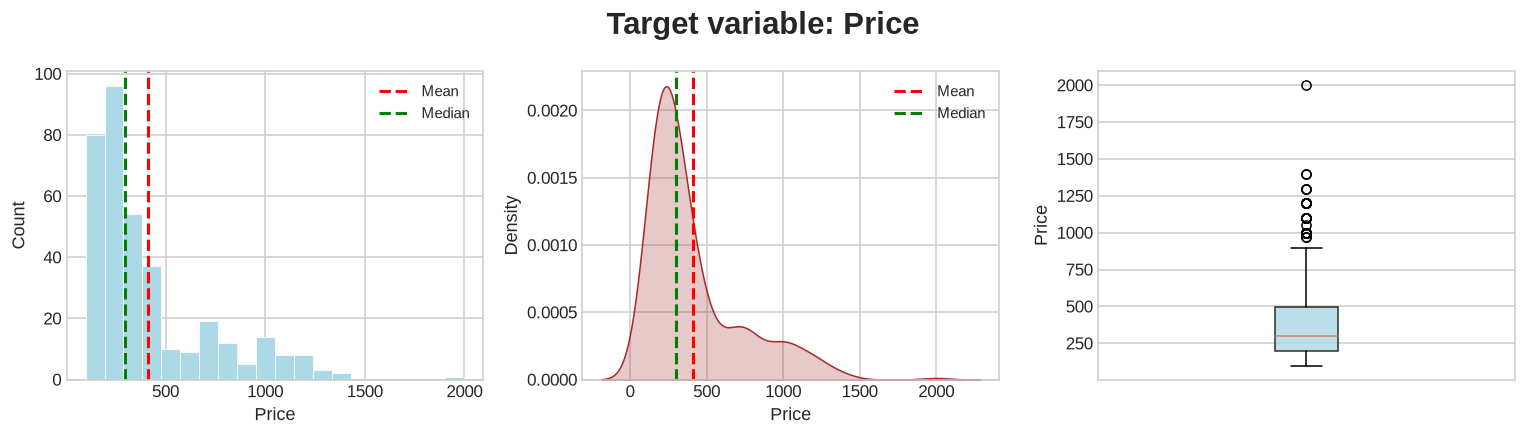

In [124]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})

fig,axes=plt.subplots(1,3 , figsize=(14,4))
fig.suptitle('Target variable: Price' , fontsize='20',fontweight='bold')

# Histogram
axes[0].hist(df['Price'], bins=20, color='lightblue', edgecolor='white', lw=0.5)
axes[0].axvline(df['Price'].mean(), color='red', ls='--',lw=2, label='Mean')
axes[0].axvline(df['Price'].median(), color='green', ls='--', lw=2, label='Median')
axes[0].set_xlabel("Price")
axes[0].set_ylabel('Count')
axes[0].legend(fontsize=10)
 
# KDE
sns.kdeplot(df['Price'], ax=axes[1],fill=True, color='brown')
axes[1].axvline(df['Price'].mean(), color='red', ls='--',lw=2, label='Mean')
axes[1].axvline(df['Price'].median(), color='green', ls='--', lw=2, label='Median')
axes[1].set_xlabel('Price')
axes[1].legend(fontsize=10)

# Box Plot
axes[2].boxplot(df['Price'],patch_artist=True, boxprops=dict(facecolor='lightblue',alpha=0.8))
axes[2].set_ylabel('Price')
axes[2].set_xticks([])

plt.tight_layout()
plt.savefig("Target_variable_pirce.png", bbox_inches="tight", dpi=110)
plt.show()

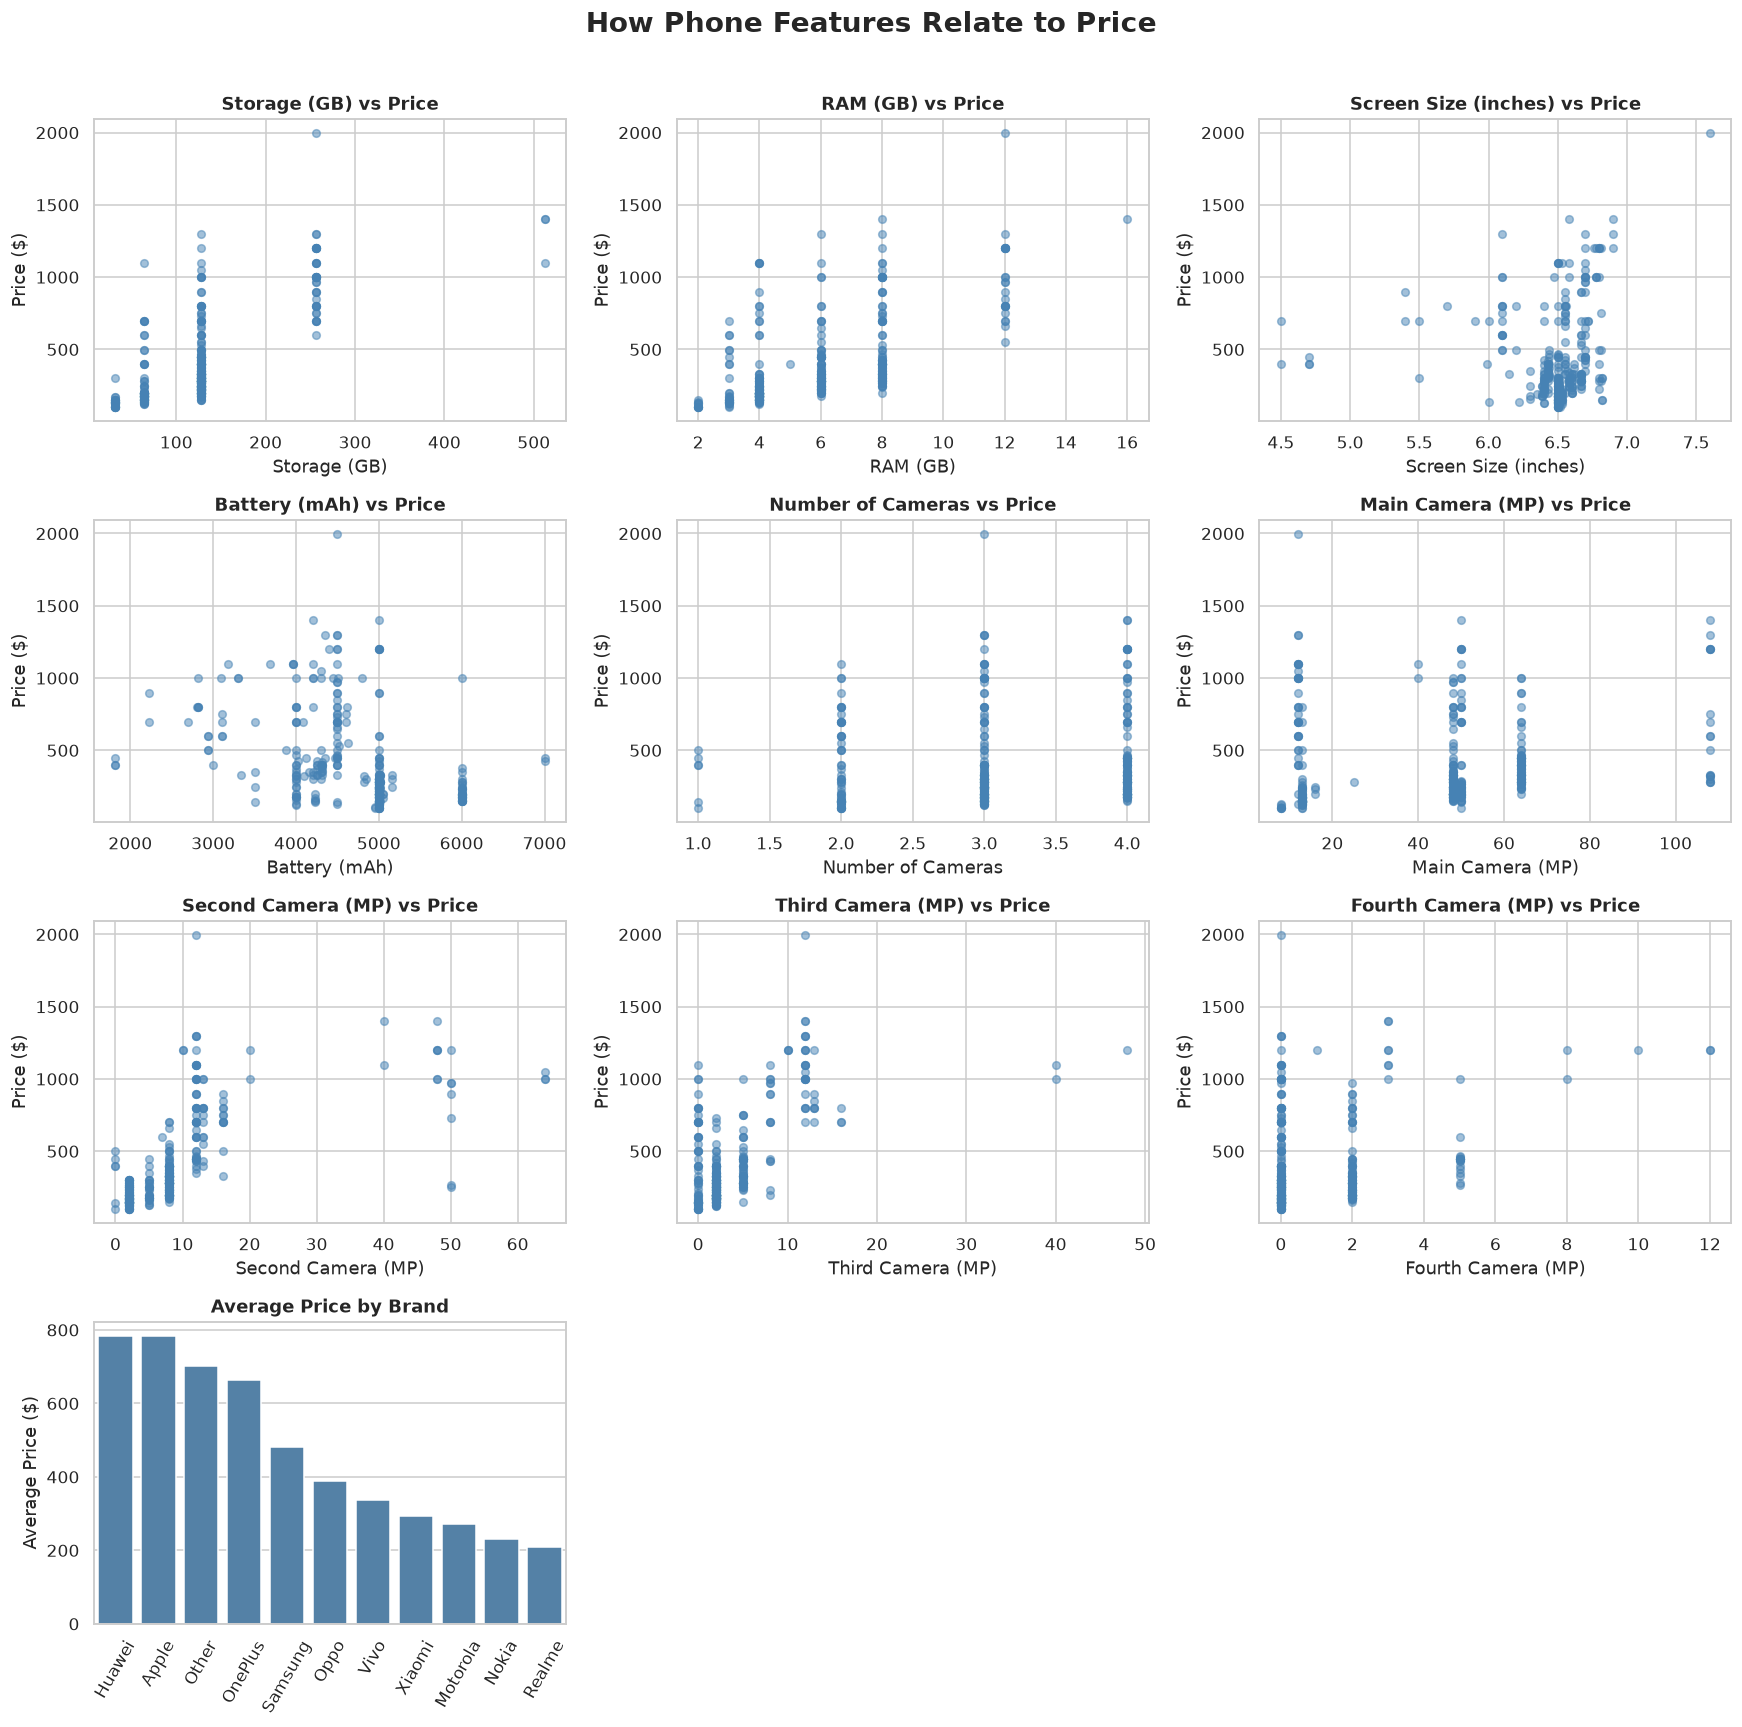

In [125]:
sns.set_theme(style="whitegrid")

feats = ['Storage', 'RAM', 'Screen_size', 'Battery_cap',
         'num_camera', 'main_camera_mp', 'second_camera_mp',
         'third_camera_mp', 'fourth_camera_mp']

labels = ["Storage (GB)", "RAM (GB)", "Screen Size (inches)", "Battery (mAh)",
          "Number of Cameras", "Main Camera (MP)", "Second Camera (MP)",
          "Third Camera (MP)", "Fourth Camera (MP)"]

# 3 columns x 4 rows = 12 panels (9 scatter plots + 1 bar chart + 2 spare)
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
fig.suptitle('How Phone Features Relate to Price', fontsize=18, fontweight='bold')
axes = axes.flatten()

# Scatter plots
for ax, feat, label in zip(axes, feats, labels):
    ax.scatter(df[feat], df['Price'], alpha=0.5, s=25, color='steelblue')
    ax.set_title(f'{label} vs Price', fontsize=12)
    ax.set_xlabel(label)
    ax.set_ylabel('Price ($)')

# Bar chart: average price by brand
brand_avg_price = (df.groupby("Brand")['Price']
                     .mean()
                     .sort_values(ascending=False)
                     .reset_index())

bar_ax = axes[len(feats)]
sns.barplot(data=brand_avg_price, x='Brand', y='Price', ax=bar_ax, color='steelblue')
bar_ax.set_title('Average Price by Brand', fontsize=12)
bar_ax.set_xlabel('')
bar_ax.set_ylabel('Average Price ($)')
bar_ax.tick_params(axis='x', rotation=60)

# Hide the unused panels
for ax in axes[len(feats) + 1:]:
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("feature_vs_price.png", bbox_inches="tight", dpi=110)
plt.show()

# CORRELATION ANALYSIS

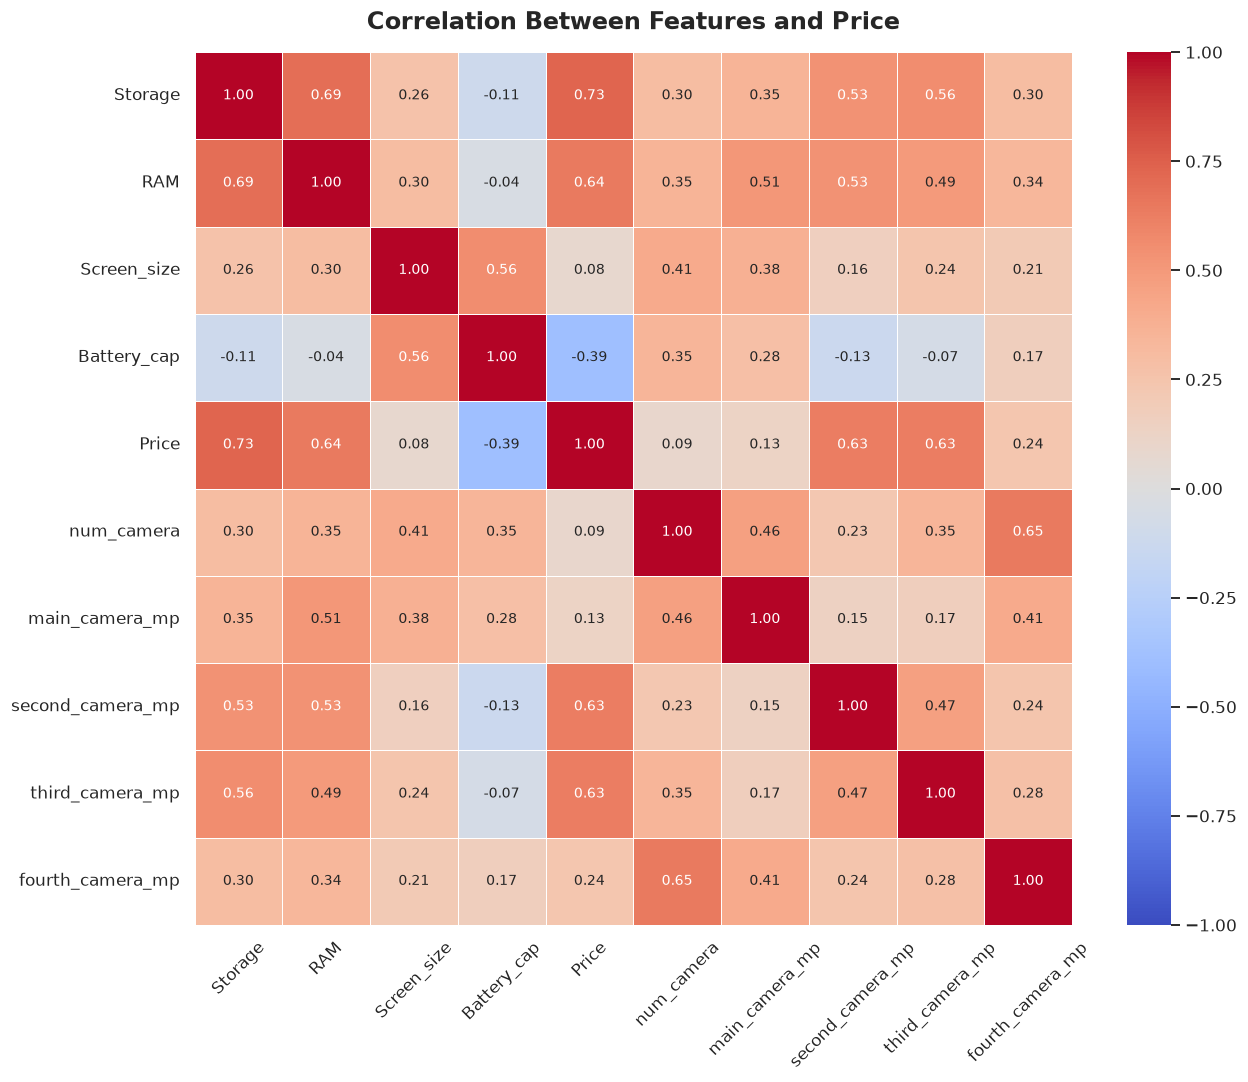

In [126]:
fig, ax = plt.subplots(figsize=(12, 10))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5,
            annot_kws={'size': 9}, ax=ax)

ax.set_title("Correlation Between Features and Price", fontsize=16, fontweight='bold', pad=15)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig("correlation_heatmap.png", bbox_inches="tight", dpi=110)
plt.show()

# SAVE THE CLEANED DATA

In [127]:
assert df.isna().sum().sum() == 0, "cleaned data should have no missing values"
df.to_csv("../data/processed/mobile_phone_price_clean.csv", index=False)
print("Saved cleaned data:", df.shape)

OSError: Cannot save file into a non-existent directory: '../data/processed'